# Simulación de Colas Independientes M/M/1 — Solución del Problema Bancario (Banco de Colombia)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Camilo-Alberto-Palacio/Simulacion-Colas-Banco-MM1/blob/main/Simulacion_Colas_Banco_Colab.ipynb)

---
### Institución Universitaria Digital de Antioquia (IU Digital)
* **Facultad:** Facultad de Ingeniería — Ingeniería de Software y Datos
* **Asignatura:** Simulación — `PREICA2602B020045` (Módulo 2 — Actividad Didáctica 2-M3)
* **Docente:** Dr. Julián Andrés Loaiza López
* **Grupo:** 25 · **Sede:** Medellín, Antioquia · **Fecha:** Noviembre de 2026

#### Integrantes del Equipo:
1. **Adriana Andrea Agudelo Agudelo**
2. **Camilo Alberto Palacios Turriago**
3. **Juan Daniel Pulgarin García**
4. **Ruben Dario Jaramillo Cervantes**

---

## 1. Planteamiento del Problema y Formulación Matemática M/M/1 y M/G/1

El **Banco de Colombia** busca evaluar el desempeño operativo de sus **3 cajas de atención presencial** (sin cajeros electrónicos inicialmente) durante una jornada diaria de **8 horas ($480\text{ minutos}$)** para decidir si debe especializar cajeros (**1 retiro + 2 pagos**, **2 retiros + 1 pago**), mantener **3 cajas mixtas**, o **incorporar un 4.º cajero físico o electrónico**.

Cada cajero opera como una cola independiente **$M/M/1$** bajo disciplina **FCFS** (*First-Come, First-Served*), donde:
* El **70 %** de los usuarios realiza **Retiros** y el **30 %** realiza **Consignaciones o pagos**.
* Las llegadas y tiempos de servicio siguen distribuciones **Exponenciales** parametrizadas por perfil de velocidad (**Rápido, Normal, Lento, Muy lento**) según las Tablas 1 y 2.

Para cada servidor independiente con tasa de llegada $\lambda_c$ y tasa de servicio $\mu_c$, la estabilidad exige $\rho_c = \lambda_c / \mu_c < 1$, aplicándose la **Ley de Little** y la extensión **Pollaczek–Khinchine M/G/1** (debido a la hiperexponencialidad de la mezcla):
$$L_q = \frac{\rho^2}{1 - \rho}, \qquad W_q^{\text{M/M/1}} = \frac{L_q}{\lambda_c} = \frac{\rho}{\mu_c(1 - \rho)}, \qquad W = W_q + \frac{1}{\mu_c}, \qquad W_q^{\text{M/G/1}} = \frac{\lambda_c\,\mathbb{E}[S^2]}{2(1 - \rho)}$$

In [1]:
from collections import deque
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (13.2, 5.2)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.linestyle"] = ":"
plt.rcParams["grid.alpha"] = 0.6

BANK_MINUTES = 480.0
ACTION_PROBS = {"Retiro": 0.70, "Pago": 0.30}
USER_TYPES = ["Rápido", "Normal", "Lento", "Muy lento"]

SERVICE_MEANS = {
    "Retiro": {"Rápido": 1.0, "Normal": 2.0, "Lento": 3.0, "Muy lento": 4.0},
    "Pago":   {"Rápido": 3.0, "Normal": 3.0, "Lento": 5.0, "Muy lento": 7.0},
}
ARRIVAL_MEANS = {
    "Retiro": {"Rápido": 1.0, "Normal": 2.0, "Lento": 3.0, "Muy lento": 3.0},
    "Pago":   {"Rápido": 1.0, "Normal": 2.0, "Lento": 3.0, "Muy lento": 4.0},
}
USER_TYPE_PROBS = {
    "Retiro": {"Rápido": 0.23, "Normal": 0.40, "Lento": 0.17, "Muy lento": 0.20},
    "Pago":   {"Rápido": 0.10, "Normal": 0.20, "Lento": 0.30, "Muy lento": 0.40},
}

SCENARIOS = {
    "E1_3_Mixtas": ("3 Mixtas", [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto")]),
    "E2_1R_2P":    ("1R + 2P",  [("Cajero 1 (Retiro)", "Retiro"), ("Cajero 2 (Pago)", "Pago"), ("Cajero 3 (Pago)", "Pago")]),
    "E3_2R_1P":    ("2R + 1P",  [("Cajero 1 (Retiro)", "Retiro"), ("Cajero 2 (Retiro)", "Retiro"), ("Cajero 3 (Pago)", "Pago")]),
    "E4a_4_Mixtas":("4 Mixtas", [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto"), ("Cajero 4", "Mixto")]),
    "E4b_2R_2P":   ("2R + 2P",  [("Cajero 1 (Retiro)", "Retiro"), ("Cajero 2 (Retiro)", "Retiro"), ("Cajero 3 (Pago)", "Pago"), ("Cajero 4 (Pago)", "Pago")]),
}

def expected_service_moments(role: str):
    if role == "Mixto":
        e1 = sum(ACTION_PROBS[a] * sum(USER_TYPE_PROBS[a][u] * SERVICE_MEANS[a][u] for u in USER_TYPES) for a in ACTION_PROBS)
        e2 = sum(ACTION_PROBS[a] * sum(USER_TYPE_PROBS[a][u] * 2.0 * (SERVICE_MEANS[a][u] ** 2) for u in USER_TYPES) for a in ACTION_PROBS)
        return e1, e2
    e1 = sum(USER_TYPE_PROBS[role][u] * SERVICE_MEANS[role][u] for u in USER_TYPES)
    e2 = sum(USER_TYPE_PROBS[role][u] * 2.0 * (SERVICE_MEANS[role][u] ** 2) for u in USER_TYPES)
    return e1, e2

def theoretical_scenario_wq(cajeros_cfg):
    e_ia = sum(ACTION_PROBS[a] * sum(USER_TYPE_PROBS[a][u] * ARRIVAL_MEANS[a][u] for u in USER_TYPES) for a in ACTION_PROBS)
    lam_tot = 1.0 / e_ia
    counts = {}
    for _, r in cajeros_cfg:
        counts[r] = counts.get(r, 0) + 1
    wq_mm1, wq_mg1, total_l = 0.0, 0.0, 0.0
    for _, role in cajeros_cfg:
        lam_c = (lam_tot if role == "Mixto" else lam_tot * ACTION_PROBS[role]) / counts[role]
        es, es2 = expected_service_moments(role)
        mu_c = 1.0 / es
        rho = lam_c / mu_c
        w_frac = lam_c / lam_tot
        wq_mm1 += w_frac * (rho / (mu_c * (1.0 - rho)))
        wq_mg1 += w_frac * ((lam_c * es2) / (2.0 * (1.0 - rho)))
        total_l += lam_c
    return wq_mm1, wq_mg1

e_ia = sum(ACTION_PROBS[a] * sum(USER_TYPE_PROBS[a][u] * ARRIVAL_MEANS[a][u] for u in USER_TYPES) for a in ACTION_PROBS)
lam_total = 1.0 / e_ia
print(f"E[IA] = {e_ia:.3f} min | λ_global = {lam_total:.4f} cli/min (~{lam_total*BANK_MINUTES:.1f} usuarios/8h)")
print(f"E[S_Retiro] = {expected_service_moments('Retiro')[0]:.2f} min | E[S_Pago] = {expected_service_moments('Pago')[0]:.2f} min | E[S_Mix] = {expected_service_moments('Mixto')[0]:.3f} min")

E[IA] = 2.398 min | λ_global = 0.4170 cli/min (~200.2 usuarios/8h)
E[S_Retiro] = 2.34 min | E[S_Pago] = 5.20 min | E[S_Mix] = 3.198 min


## 2. Motor DES (M/M/1 Independiente, JSQ No Clarividente e IC95% exacto *t* de Student)

Implementamos:
* **Generación reproducible** (`PCG64`, semilla base `42`, jornadas de `480 min`) con **Números Aleatorios Comunes (CRN)** entre escenarios.
* **Descomposición equiprobable de Poisson (`1/k`)** (`random_mm1`) para preservar cajeros independientes M/M/1, frente a **Join-the-Shortest-Queue (`shortest_queue`) no clarividente** (el usuario observa únicamente el número de personas presentes en fila o servicio sin conocer tiempos futuros de atención).
* **Cuantiles exactos de la distribución *t* de Student** (sin aproximaciones asintóticas de `1.96`) para intervalos de confianza al 95 % y cálculo iterativo del tamaño muestral requerido ($n^*$).

In [2]:
def _betacf(a: float, b: float, x: float) -> float:
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c, d = 1.0, 1.0 - qab * x / qap
    d = 1.0 / (d if abs(d) >= 1e-300 else 1e-300)
    h = d
    for m in range(1, 201):
        m2 = 2 * m
        for aa in (m * (b - m) * x / ((qam + m2) * (a + m2)), -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))):
            d = 1.0 + aa * d
            d = 1.0 / (d if abs(d) >= 1e-300 else 1e-300)
            c = 1.0 + aa / (c if abs(c) >= 1e-300 else 1e-300)
            c = c if abs(c) >= 1e-300 else 1e-300
            h *= d * c
            if m > 1 and abs(d * c - 1.0) < 3e-14:
                return h
    return h

def _betainc(a: float, b: float, x: float) -> float:
    if x <= 0.0: return 0.0
    if x >= 1.0: return 1.0
    bt = math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + a * math.log(x) + b * math.log(1.0 - x))
    return (bt * _betacf(a, b, x) / a) if x < (a + 1.0) / (a + b + 2.0) else (1.0 - bt * _betacf(b, a, 1.0 - x) / b)

def t_crit_95(df: int) -> float:
    target, lo, hi = 0.05, 0.0, 20.0
    while _betainc(0.5 * df, 0.5, df / (df + hi * hi)) > target:
        hi *= 2.0
    for _ in range(90):
        mid = 0.5 * (lo + hi)
        if _betainc(0.5 * df, 0.5, df / (df + mid * mid)) > target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def ci95_student_t(values):
    arr = np.asarray([float(v) for v in values if not np.isnan(v)], dtype=float)
    n = len(arr)
    m = float(np.mean(arr))
    if n <= 1: return m, 0.0, m, m
    sd = float(np.std(arr, ddof=1))
    half = t_crit_95(n - 1) * sd / np.sqrt(n)
    return m, sd, m - half, m + half

def generate_day_arrivals(seed: int):
    rng = np.random.default_rng(seed)
    actions = list(ACTION_PROBS.keys())
    act_p = [ACTION_PROBS[a] for a in actions]
    utype_p = {a: [USER_TYPE_PROBS[a][u] for u in USER_TYPES] for a in actions}
    arrivals, t = [], 0.0
    while True:
        act = str(rng.choice(actions, p=act_p))
        ut = str(rng.choice(USER_TYPES, p=utype_p[act]))
        t += float(rng.exponential(ARRIVAL_MEANS[act][ut]))
        if t > BANK_MINUTES:
            break
        srv = float(rng.exponential(SERVICE_MEANS[act][ut]))
        arrivals.append((t, act, ut, srv))
    return arrivals

def simulate_scenario_replica(cajeros_cfg, arrivals, routing_seed: int, routing_mode: str = "random_mm1"):
    rng = np.random.default_rng(routing_seed)
    k = len(cajeros_cfg)
    queues = [[] for _ in range(k)]
    dep_q = [deque() for _ in range(k)]
    free_t = [0.0 for _ in range(k)]
    elig_map = {a: [i for i, (_, r) in enumerate(cajeros_cfg) if r == "Mixto" or r == a] for a in ACTION_PROBS}

    for t_arr, act, ut, srv in arrivals:
        elig = elig_map[act]
        if len(elig) == 1:
            idx = elig[0]
        elif routing_mode == "random_mm1":
            idx = elig[int(rng.integers(0, len(elig)))]
        elif routing_mode == "shortest_queue":
            for i in elig:
                while dep_q[i] and dep_q[i][0] <= t_arr:
                    dep_q[i].popleft()
            min_len = min(len(dep_q[i]) for i in elig)
            tied = [i for i in elig if len(dep_q[i]) == min_len]
            idx = tied[0] if len(tied) == 1 else tied[int(rng.integers(0, len(tied)))]
        else:
            raise ValueError(routing_mode)
        queues[idx].append((t_arr, act, ut, srv))
        end_t = max(t_arr, free_t[idx]) + srv
        free_t[idx] = end_t
        dep_q[idx].append(end_t)

    cashier_stats = {}
    all_w, all_s, all_sys = [], [], []
    w_by_act = {a: [] for a in ACTION_PROBS}
    w_by_typ = {u: [] for u in USER_TYPES}
    counts_u = {u: 0 for u in USER_TYPES}
    counts_in_turn = {u: 0 for u in USER_TYPES}
    completed_turn = 0

    for idx, (cname, role) in enumerate(cajeros_cfg):
        ft = 0.0
        ws, ss, syss = [], [], []
        cu = {u: 0 for u in USER_TYPES}
        for t_arr, act, ut, srv in queues[idx]:
            st = max(t_arr, ft)
            wt = st - t_arr
            ft = st + srv
            ws.append(wt); ss.append(srv); syss.append(wt + srv)
            all_w.append(wt); all_s.append(srv); all_sys.append(wt + srv)
            w_by_act[act].append(wt); w_by_typ[ut].append(wt)
            cu[ut] += 1; counts_u[ut] += 1
            if ft <= BANK_MINUTES:
                completed_turn += 1
                counts_in_turn[ut] += 1
        heff = max(BANK_MINUTES, ft)
        cashier_stats[cname] = {
            "rol": role, "usuarios": len(queues[idx]),
            "mean_s": float(np.mean(ss)) if ss else 0.0,
            "mean_wq": float(np.mean(ws)) if ws else 0.0,
            "mean_w": float(np.mean(syss)) if syss else 0.0,
            "rho": float(np.sum(ss) / heff),
            "counts_u": cu,
        }
    return {
        "total_usuarios": len(arrivals), "atendidos_turno": completed_turn,
        "counts_u": counts_u, "counts_in_turn": counts_in_turn,
        "mean_wq": float(np.mean(all_w)), "mean_s": float(np.mean(all_s)), "mean_w": float(np.mean(all_sys)),
        "wq_retiro": float(np.mean(w_by_act["Retiro"])), "wq_pago": float(np.mean(w_by_act["Pago"])),
        "wq_rapido": float(np.mean(w_by_typ["Rápido"])), "wq_normal": float(np.mean(w_by_typ["Normal"])),
        "wq_lento": float(np.mean(w_by_typ["Lento"])), "wq_muy_lento": float(np.mean(w_by_typ["Muy lento"])),
        "peor_wq": max(v["mean_wq"] for v in cashier_stats.values()),
        "rho_med": float(np.mean([v["rho"] for v in cashier_stats.values()])),
        "rho_max": float(np.max([v["rho"] for v in cashier_stats.values()])),
        "cashiers": cashier_stats,
    }

def run_experiment(num_replicas: int = 10, base_seed: int = 42, routing_mode: str = "random_mm1"):
    shared_arr = {r: generate_day_arrivals(base_seed + r) for r in range(1, num_replicas + 1)}
    rep_rows, caj_rows, prof_rows = [], [], []
    for s_idx, (skey, (short_name, cfg)) in enumerate(SCENARIOS.items()):
        for r in range(1, num_replicas + 1):
            arr = shared_arr[r]
            res = simulate_scenario_replica(cfg, arr, base_seed * 100 + s_idx * 1000 + r, routing_mode)
            rep_rows.append({
                "escenario": skey, "nombre": short_name, "replica": r,
                "total": res["total_usuarios"], "en_turno": res["atendidos_turno"],
                "Rápido": res["counts_u"]["Rápido"], "Normal": res["counts_u"]["Normal"],
                "Lento": res["counts_u"]["Lento"], "Muy lento": res["counts_u"]["Muy lento"],
                "Rápido_turno": res["counts_in_turn"]["Rápido"], "Normal_turno": res["counts_in_turn"]["Normal"],
                "Lento_turno": res["counts_in_turn"]["Lento"], "Muy lento_turno": res["counts_in_turn"]["Muy lento"],
                "Wq": res["mean_wq"], "Wq_Retiro": res["wq_retiro"], "Wq_Pago": res["wq_pago"],
                "Wq_Rápido": res["wq_rapido"], "Wq_Normal": res["wq_normal"],
                "Wq_Lento": res["wq_lento"], "Wq_Muy_lento": res["wq_muy_lento"],
                "S": res["mean_s"], "W": res["mean_w"], "Peor_Wq": res["peor_wq"],
                "rho_med": res["rho_med"], "rho_max": res["rho_max"],
            })
            for cname, cv in res["cashiers"].items():
                caj_rows.append({
                    "escenario": skey, "nombre": short_name, "replica": r,
                    "cajero": cname, "rol": cv["rol"], "usuarios": cv["usuarios"],
                    "S": cv["mean_s"], "Wq": cv["mean_wq"], "W": cv["mean_w"], "rho": cv["rho"],
                    "Rápido": cv["counts_u"]["Rápido"], "Normal": cv["counts_u"]["Normal"],
                    "Lento": cv["counts_u"]["Lento"], "Muy lento": cv["counts_u"]["Muy lento"],
                })
            if skey == "E1_3_Mixtas":
                c8 = {(a, u): 0 for a in ACTION_PROBS for u in USER_TYPES}
                for _, act, ut, _ in arr:
                    c8[(act, ut)] += 1
                for (a, u), cnt in c8.items():
                    prof_rows.append({"replica": r, "accion": a, "tipo": u, "cantidad": cnt, "prop": cnt / len(arr)})
    return pd.DataFrame(rep_rows), pd.DataFrame(caj_rows), pd.DataFrame(prof_rows)

df_rep10, df_caj10, df_prof10 = run_experiment(num_replicas=10, base_seed=42)
print("Ejecución de 10 réplicas oficiales completada (t_0.975,9 =", round(t_crit_95(9), 4), ").")

Ejecución de 10 réplicas oficiales completada (t_0.975,9 = 2.2622 ).


## 3. Resultados de los Puntos 1, 2, 3 y Tamaño Muestral ($n^*$) sobre 10 Réplicas

In [3]:
# Punto 1: Cajero con menor y mayor tiempo promedio de atención en el escenario base (3 Mixtas)
base_caj = df_caj10[df_caj10["escenario"] == "E1_3_Mixtas"].groupby("cajero", sort=False).agg(
    Usuarios_Prom=("usuarios", "mean"),
    Servicio_S_min=("S", "mean"),
    Espera_Wq_min=("Wq", "mean"),
    Atencion_W_min=("W", "mean"),
    Utilizacion_rho=("rho", "mean"),
).round(3)
print("=== PUNTO 1: DESEMPEÑO POR CAJERO (ESCENARIO BASE 3 MIXTAS, 10 RÉPLICAS) ===")
display(base_caj)

# Punto 2: Promedio en totalidad de cajeros, por cajero y los 8 subperfiles
base_rep = df_rep10[df_rep10["escenario"] == "E1_3_Mixtas"][["replica", "total", "en_turno", "Rápido", "Normal", "Lento", "Muy lento", "Wq", "W"]].copy()
print("\n=== PUNTO 2: PROMEDIO DIARIO POR TIPO EN LA SUCURSAL Y POR CAJERO ===")
pts2_df = pd.DataFrame({
    "Sucursal_Total_Prom": base_rep[["Rápido", "Normal", "Lento", "Muy lento"]].mean(),
    "DE_10_Replicas": base_rep[["Rápido", "Normal", "Lento", "Muy lento"]].std(ddof=1),
    "Promedio_Por_Cajero": base_rep[["Rápido", "Normal", "Lento", "Muy lento"]].mean() / 3.0,
}).round(2)
display(pts2_df)

prof_summary = df_prof10.groupby(["accion", "tipo"], sort=False).agg(
    Total_10R=("cantidad", "sum"),
    Prom_Dia=("cantidad", "mean"),
    Prop_Emp_pct=("prop", lambda s: s.mean() * 100),
).round(2)
prof_summary["Prop_Teor_pct"] = [ACTION_PROBS[a] * USER_TYPE_PROBS[a][u] * 100 for a, u in prof_summary.index]
print("Desglose de los 8 perfiles (Acción × Tipo):")
display(prof_summary.round(2))

# Punto 3: Detalle por réplica, mínimos por tipo y modelo con menor atención en turno de 480 min
print("\n=== PUNTO 3: TOTAL POR RÉPLICA, MÍNIMOS Y MODELO CON MENOR ATENCIÓN ===")
display(base_rep.round(2))
for u in USER_TYPES:
    idx_min = base_rep[u].idxmin()
    print(f"  - Mínimo en réplicas ({u:10s}): {int(base_rep.loc[idx_min, u])} usuarios en Réplica {int(base_rep.loc[idx_min, 'replica'])}")

turn_cols = ["en_turno", "Rápido_turno", "Normal_turno", "Lento_turno", "Muy lento_turno"]
turn_by_model = df_rep10.groupby("nombre", sort=False)[turn_cols].sum()
print("\nTotal completados dentro del turno de 480 min por modelo (suma 10 réplicas):")
display(turn_by_model)

# Tamaño muestral requerido (n*) desde piloto n0 = 10
req_rows = []
for skey, (short_n, _) in SCENARIOS.items():
    sub = df_rep10[df_rep10["escenario"] == skey]
    wqm, wqsd, wql, wqu = ci95_student_t(sub["Wq"])
    wm, wsd, _, _ = ci95_student_t(sub["W"])
    um, usd, _, _ = ci95_student_t(sub["total"])
    def req_n(s, tol):
        n = max(2, math.ceil((t_crit_95(9) * s / tol) ** 2))
        for _ in range(30):
            nn = max(2, math.ceil((t_crit_95(n - 1) * s / tol) ** 2))
            if nn == n: break
            n = nn
        return n
    req_rows.append({
        "Escenario": short_n, "Semiamp_Wq_n10": round(0.5*(wqu - wql), 2), "DE_Wq": round(wqsd, 2),
        "n_req_Wq_050m": req_n(wqsd, 0.50), "n_req_W_5pct": req_n(wsd, 0.05 * wm), "n_req_Usr_5": req_n(usd, 5.0),
    })
print("\n=== CÁLCULO ITERATIVO DE RÉPLICAS NECESARIAS (n*, 95% t DE STUDENT) ===")
display(pd.DataFrame(req_rows).set_index("Escenario"))

=== PUNTO 1: DESEMPEÑO POR CAJERO (ESCENARIO BASE 3 MIXTAS, 10 RÉPLICAS) ===


,Usuarios_Prom,Servicio_S_min,Espera_Wq_min,Atencion_W_min,Utilizacion_rho
cajero,,,,,
Cajero 1,71.0,3.226,4.263,7.490,0.475
Cajero 2,66.9,2.882,3.335,6.217,0.404
Cajero 3,70.4,3.155,3.579,6.734,0.455



=== PUNTO 2: PROMEDIO DIARIO POR TIPO EN LA SUCURSAL Y POR CAJERO ===


,Sucursal_Total_Prom,DE_10_Replicas,Promedio_Por_Cajero
Rápido,41.3,4.76,13.77
Normal,72.0,6.34,24.00
Lento,43.1,6.69,14.37
Muy lento,51.9,7.55,17.30


Desglose de los 8 perfiles (Acción × Tipo):

Total_10R  Prom_Dia  Prop_Emp_pct  Prop_Teor_pct
accion tipo                                                       
Retiro Rápido           343      34.3         16.43           16.1
       Normal           589      58.9         28.40           28.0
       Lento            248      24.8         11.87           11.9
       Muy lento        292      29.2         14.00           14.0
Pago   Rápido            70       7.0          3.38            3.0
       Normal           131      13.1          6.24            6.0
       Lento            183      18.3          8.81            9.0
       Muy lento        227      22.7         10.87           12.0

... (2 outputs left out)

  - Mínimo en réplicas (Rápido    ): 30 usuarios en Réplica 5
  - Mínimo en réplicas (Normal    ): 62 usuarios en Réplica 5
  - Mínimo en réplicas (Lento     ): 34 usuarios en Réplica 9
  - Mínimo en réplicas (Muy lento ): 44 usuarios en Réplica 5

Total completados dentro del turno de 480 min por modelo (suma 10 réplicas):


,en_turno,Rápido_turno,Normal_turno,Lento_turno,Muy lento_turno
nombre,,,,,
3 Mixtas,2054,409,708,428,509
1R + 2P,2051,406,709,428,508
2R + 1P,2059,408,712,427,512
4 Mixtas,2065,410,714,429,512
2R + 2P,2062,409,712,429,512



=== CÁLCULO ITERATIVO DE RÉPLICAS NECESARIAS (n*, 95% t DE STUDENT) ===


,Semiamp_Wq_n10,DE_Wq,n_req_Wq_050m,n_req_W_5pct,n_req_Usr_5
Escenario,,,,,
3 Mixtas,1.25,1.75,50,124,51
1R + 2P,0.95,1.32,30,58,51
2R + 1P,1.47,2.06,68,172,51
4 Mixtas,0.57,0.79,13,64,51
2R + 2P,0.50,0.70,10,58,51


## 4. Comparativa de Escenarios, Todos los Criterios de Espera y Validación Monte Carlo (100 Réplicas)

=== RESUMEN COMPARATIVO MULTI-CRITERIO (100 RÉPLICAS MONTE CARLO) ===


,Wq_Global,Wq_IC95_Inf,Wq_IC95_Sup,Wq_Retiro,Wq_Pago,Peor_Cajero_Wq,Sistema_W,MM1_Teor,MG1_PK,Wq_JSQ,Rho_Med_pct,Rho_Max_pct
Escenario,,,,,,,,,,,,
3 Mixtas,3.24,2.96,3.53,3.29,3.15,5.05,6.40,2.56,3.39,0.74,43.69,50.89
1R + 2P,4.94,4.43,5.46,5.91,2.49,6.47,8.11,4.28,5.06,4.45,43.63,67.36
2R + 1P,3.83,3.39,4.27,1.54,9.08,9.16,6.99,3.75,4.22,3.17,43.50,62.68
4 Mixtas,2.00,1.84,2.15,2.07,1.84,3.39,5.16,1.60,2.12,0.18,32.86,40.97
2R + 2P,1.81,1.69,1.93,1.53,2.47,3.58,4.98,1.60,1.85,0.67,32.86,40.51



Desagregación adicional de Wq por velocidad de usuario (min):


,Wq_Rápido,Wq_Normal,Wq_Lento,Wq_Muy_lento
nombre,,,,
3 Mixtas,3.79,3.28,3.08,2.92
1R + 2P,5.91,5.51,4.24,4.05
2R + 1P,3.24,2.99,4.78,4.64
4 Mixtas,2.37,2.07,1.83,1.73
2R + 2P,1.96,1.73,1.84,1.79


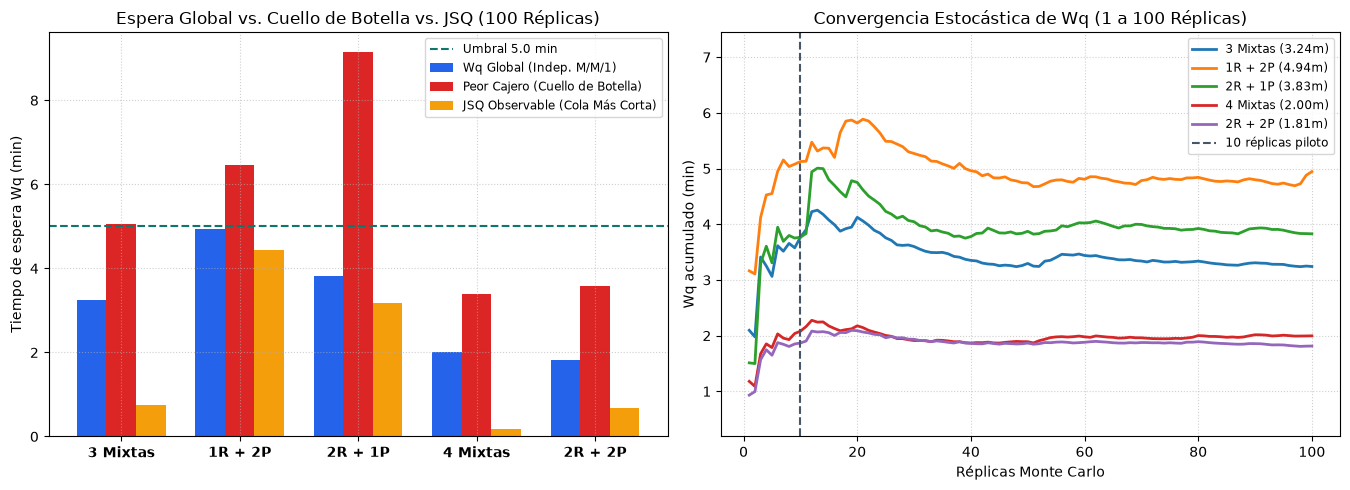

In [4]:
df_rep100, df_caj100, _ = run_experiment(num_replicas=100, base_seed=42, routing_mode="random_mm1")
df_jsq100, _, _ = run_experiment(num_replicas=100, base_seed=42, routing_mode="shortest_queue")

sum_rows = []
for skey, (short_n, cfg) in SCENARIOS.items():
    sub = df_rep100[df_rep100["escenario"] == skey]
    sub_jsq = df_jsq100[df_jsq100["escenario"] == skey]
    wqm, wqsd, wql, wqu = ci95_student_t(sub["Wq"])
    wm, _, _, _ = ci95_student_t(sub["W"])
    mm1_wq, mg1_wq = theoretical_scenario_wq(cfg)
    sum_rows.append({
        "Escenario": short_n,
        "Wq_Global": wqm, "Wq_IC95_Inf": wql, "Wq_IC95_Sup": wqu,
        "Wq_Retiro": float(sub["Wq_Retiro"].mean()), "Wq_Pago": float(sub["Wq_Pago"].mean()),
        "Peor_Cajero_Wq": float(sub["Peor_Wq"].mean()),
        "Sistema_W": wm, "MM1_Teor": mm1_wq, "MG1_PK": mg1_wq,
        "Wq_JSQ": float(sub_jsq["Wq"].mean()),
        "Rho_Med_pct": float(sub["rho_med"].mean() * 100),
        "Rho_Max_pct": float(sub["rho_max"].mean() * 100),
    })
summary = pd.DataFrame(sum_rows).set_index("Escenario").round(2)
print("=== RESUMEN COMPARATIVO MULTI-CRITERIO (100 RÉPLICAS MONTE CARLO) ===")
display(summary)

crit_typ = df_rep100.groupby("nombre", sort=False)[["Wq_Rápido", "Wq_Normal", "Wq_Lento", "Wq_Muy_lento"]].mean().round(2)
print("\nDesagregación adicional de Wq por velocidad de usuario (min):")
display(crit_typ)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 5.0))
x = np.arange(len(summary))
ax1.bar(x - 0.25, summary["Wq_Global"], width=0.25, color="#2563EB", label="Wq Global (Indep. M/M/1)")
ax1.bar(x,        summary["Peor_Cajero_Wq"], width=0.25, color="#DC2626", label="Peor Cajero (Cuello de Botella)")
ax1.bar(x + 0.25, summary["Wq_JSQ"], width=0.25, color="#F59E0B", label="JSQ Observable (Cola Más Corta)")
ax1.axhline(5.0, color="#0F766E", linestyle="--", label="Umbral 5.0 min")
ax1.set_xticks(x); ax1.set_xticklabels(summary.index, fontweight="bold")
ax1.set_ylabel("Tiempo de espera Wq (min)")
ax1.set_title("Espera Global vs. Cuello de Botella vs. JSQ (100 Réplicas)")
ax1.legend(fontsize=8.5)

c_min, c_max = float("inf"), float("-inf")
for skey, (short_n, _) in SCENARIOS.items():
    sub = df_rep100[df_rep100["escenario"] == skey].sort_values("replica")
    cm = sub["Wq"].expanding().mean()
    c_min, c_max = min(c_min, float(cm.min())), max(c_max, float(cm.max()))
    ax2.plot(sub["replica"], cm, linewidth=2.0, label=f"{short_n} ({cm.iloc[-1]:.2f}m)")
ax2.axvline(10, color="#475569", linestyle="--", label="10 réplicas piloto")
pad = max(0.35, (c_max - c_min) * 0.15)
ax2.set_ylim(max(0.0, c_min - pad), c_max + pad * 2.1)
ax2.set_xlabel("Réplicas Monte Carlo")
ax2.set_ylabel("Wq acumulado (min)")
ax2.set_title("Convergencia Estocástica de Wq (1 a 100 Réplicas)")
ax2.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

## 5. Conclusiones Ejecutivas para el Banco de Colombia

1. **Cajero con menor y mayor atención (Base 3 Mixtas, 10 réplicas):** El **Cajero 2** registró el menor tiempo medio (`S = 2.882 min`, `W = 6.217 min`), mientras que el **Cajero 1** registró el mayor (`S = 3.226 min`, `W = 7.490 min`), debido a la varianza natural de las colas M/M/1 independientes.
2. **Suficiencia de réplicas ($n^*$):** Con $\varepsilon = \pm 0.50\text{ min}$ en $W_q$ al 95 % *t* de Student, las configuraciones de 3 cajas requieren entre `30` (`1R+2P`), `50` (`3 Mixtas`) y `68` (`2R+1P`) réplicas, razón por la cual las `100` réplicas Monte Carlo garantizan plena convergencia estadística.
3. **Necesidad de un 4.º cajero físico o cajero electrónico:** **No es necesario** ampliar a 4 posiciones si se mantienen 3 cajas mixtas: en todos los criterios de espera (`Wq_Global = 3.24 min`, `Retiro = 3.29 min`, `Pago = 3.15 min`, perfiles `2.92–3.79 min`, `JSQ = 0.74 min`), el servicio opera holgadamente bajo `5.0 min` con apenas `43.7%` de utilización (`56.3%` de ocio). Un 4.º cajero desploma la ocupación a `32.9%` (`67.1%` ocio) por un ahorro marginal de `1.24 min`.
4. **Asignación óptima de cajas exclusivas (Pagos vs. Retiros):** La configuración óptima con 3 cajeros es **3 cajas mixtas (`0 exclusivos de retiro` / `0 exclusivos de pago`)** por el efecto *pooling*. Bajo especialización rígida de 3 cajas, `1R + 2P` sobrecarga retiros (`5.91 min`; global `4.94 min`) y `2R + 1P` dispara la espera del único cajero de pagos hasta **`9.08 min`** (`W = 14.25 min` en sistema; peor promedio diario de réplica `9.16 min`).